# Tutorial: a real CHO fed-batch dataset through the model (ZeLa example)

This notebook walks through one complete, real example so you can see what goes in,
what happens inside, and what comes out.

**The dataset.** Wild-type CHO versus *ZeLa*, a CHO line engineered so it secretes no
lactate. Eight fed-batch bioreactors (3 WT, 5 ZeLa), sampled on days 2-14. It was
published together with the iCHO3K model, so it is the closest thing to a reference
example for this model. For every sample there are two kinds of measurement:

| Layer | What it is | What the model does with it |
|---|---|---|
| Transcriptomics (TPM per gene) | which enzymes the cell is making | discourages flux through reactions whose genes are barely expressed (GIMME) |
| Exchange rates (mmol/gDW/h) | what the cell takes up and secretes | fixes the model's inputs and outputs to what was measured |

The model then fills in what cannot be measured: the fluxes *inside* the cell.

Run first (about 5 minutes):
```bash
python scripts/prepare_zela.py
python -m gems.pipeline --raw data/zela --crosswalk data/zela/crosswalk.tsv --out results/zela
```

In [1]:
import sys, pathlib
for _c in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_c / 'src' / 'gems').is_dir():
        sys.path.insert(0, str(_c / 'src')); break

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from gems import config as C, model_setup, gene_mapping, qrate_calc, gimme_fba, escher_view as ev

RAW, OUT = C.DATA / 'zela', C.RESULTS / 'zela' / 'fluxes'
meta   = pd.read_csv(RAW / 'metadata.csv', index_col=0)
counts = pd.read_csv(RAW / 'counts.csv', index_col=0)
rates  = pd.read_csv(RAW / 'exchange_rates.csv', index_col=0)
growth = pd.read_csv(RAW / 'measured_growth.csv', index_col=0).iloc[:, 0]
COL = {'WT': '#4a6fa5', 'ZeLa': '#d1782f'}
meta.groupby(['condition', 'clone']).timepoint.apply(list).to_frame('days sampled')

days sampled
condition clone                      
WT        U1     [2, 4, 6, 8, 12, 14]
          U2     [2, 4, 6, 8, 12, 14]
          U3         [2, 4, 6, 8, 14]
ZeLa      U4            [4, 6, 8, 14]
          U5        [2, 4, 8, 12, 14]
          U6     [2, 4, 6, 8, 12, 14]
          U7         [2, 4, 6, 8, 14]
          U8     [2, 4, 6, 8, 12, 14]

## 1. The inputs

**Expression** is a genes x samples table. **Exchange rates** are one row per sample;
negative means the cell takes the compound up, positive means it secretes it. Below are
the largest rates for a wild-type and a ZeLa sample on day 4 - note lactate.

In [2]:
print('expression table:', counts.shape, ' e.g.', counts.index[100:104].tolist())
pair = rates.loc[['S2', 'S18']].T
pair.columns = ['WT day 4 (S2)', 'ZeLa day 4 (S18)']
pair.reindex(pair.abs().max(axis=1).sort_values(ascending=False).index).head(10).round(3)

expression table: (32426, 43)  e.g. ['Abtb1', 'Abtb2', 'Acaa2', 'Acaca']


,WT day 4 (S2),ZeLa day 4 (S18)
EX_lac_L_e,0.855,0.000
EX_glc_e,-0.562,-0.295
EX_nh4_e,0.106,0.137
EX_asn_L_e,-0.117,-0.131
EX_gln_L_e,-0.123,-0.127
EX_ala_L_e,0.056,0.091
EX_ser_L_e,-0.071,-0.082
EX_etoh_e,0.071,0.003
EX_pyr_e,0.003,0.065
EX_pro_L_e,-0.039,-0.048


## 2. One sample, step by step

The pipeline does three things per sample. Here they are by hand for **S2** (WT, day 4).

### Step A - from genes to reactions
Each model reaction lists the genes that catalyse it. The gene crosswalk turns the
dataset's gene symbols into the model's gene ids, then every reaction gets an
expression score (for enzyme complexes the weakest subunit counts; for alternative
enzymes the strongest).

In [3]:
model = model_setup.get_base_model()
xwalk = gene_mapping.load_crosswalk(RAW / 'crosswalk.tsv')
sid = 'S2'
scores, rep = gene_mapping.map_expression(model, counts, xwalk, sid)
print(f"model genes with expression data: {rep.n_model_genes_with_data}/{rep.n_model_genes} "
      f"({rep.model_gene_coverage:.0%});  reactions scored: {rep.n_reactions_scored}/{len(model.reactions)}")
pd.Series(scores).dropna().sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(1).to_frame('expression score')

model genes with expression data: 2685/2929 (92%);  reactions scored: 5941/8368


,expression score
AGTim,0.0
OCDCEAtr,0.0
OCDCAtr,0.0
GAPD3,6614.6
GAPD,6614.6
GAPD2,6614.6


### Step B - make the measured rates usable
Measurements are noisy. If every exchange were pinned exactly to its measured value the
model would often have no solution (for example an essential amino acid measured as
slightly *secreted*). `reconcile_rates` finds the set of exchange rates **closest to the
measurements** that the network can actually carry while growing at least as fast as
measured, and reports every change it made.

In [4]:
bounds, report = qrate_calc.reconcile_rates(model, rates.loc[sid].to_dict(), min_growth=float(growth[sid]))
print(f"total adjustment: {report.deviation.abs().sum():.3f} mmol/gDW/h across {len(report)} measured exchanges")
report.reindex(report.deviation.abs().sort_values(ascending=False).index).head(5).round(4)

total adjustment: 0.071 mmol/gDW/h across 34 measured exchanges


,reaction_id,measured,used,deviation
10,EX_etoh_e,0.0711,0.0000,-0.0711
11,EX_for_e,0.0316,0.0316,-0.0000
21,EX_leu_L_e,-0.0279,-0.0279,0.0000
27,EX_5oxpro_e,0.0092,0.0092,0.0000
9,EX_cys_L_e,-0.0040,-0.0040,0.0000


### Step C - solve for the internal fluxes (GIMME)
With inputs and outputs fixed, many internal flux patterns are still possible. GIMME
picks the one that (1) keeps growth at half of what the nutrients allow or more,
(2) uses as little flux as possible through weakly expressed reactions, and
(3) is otherwise the most economical.

In [5]:
res = gimme_fba.run_gimme(model, scores, exchange_bounds=bounds)
print(f"status: {res.status}")
print(f"growth the measured uptake can support: {res.growth_max:.4f} /h   (measured: {growth[sid]:.4f} /h)")
key = ['EX_glc_e', 'HEX1', 'PYK', 'LDH_L', 'EX_lac_L_e', 'EX_gln_L_e', 'EX_nh4_e', 'ATPS4m', C.BIOMASS_RXN]
res.fluxes.reindex([k for k in key if k in res.fluxes.index]).round(3).to_frame('flux (mmol/gDW/h)')

status: optimal
growth the measured uptake can support: 0.0484 /h   (measured: 0.0328 /h)


,flux (mmol/gDW/h)
EX_glc_e,-0.551
HEX1,0.216
PYK,0.000
LDH_L,-0.838
EX_lac_L_e,0.838
EX_gln_L_e,-0.120
EX_nh4_e,0.108
ATPS4m,0.005
biomass_cho_s,0.024


## 3. All 43 samples

Everything below reads the pipeline output in `results/zela/fluxes/`.

### 3.1 Does the model agree with the bioreactor?
Growth capacity is the fastest growth the measured nutrient uptake could support. It is
not fitted to the measured growth rate curve, only required to be at least as high, so
how closely it tracks the measurement is a real check.

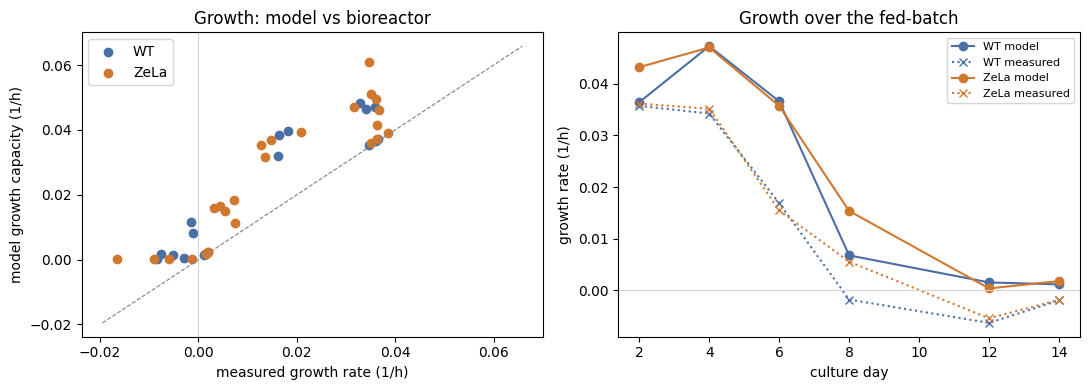

samples still growing (n=25): median capacity/measured = 1.48


In [6]:
summ = pd.read_csv(OUT / 'sample_summary.csv', index_col=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for cond, g in summ.groupby('condition'):
    ax[0].scatter(g.measured_growth, g.growth_capacity, c=COL[cond], label=cond, s=36)
lim = [min(summ.measured_growth.min(), 0) - 0.003, summ.growth_capacity.max() + 0.005]
ax[0].plot(lim, lim, c='grey', lw=0.8, ls='--'); ax[0].axvline(0, c='lightgrey', lw=0.8)
ax[0].set(xlabel='measured growth rate (1/h)', ylabel='model growth capacity (1/h)',
          title='Growth: model vs bioreactor'); ax[0].legend()
for cond, g in summ.groupby('condition'):
    m = g.groupby('timepoint')[['growth_capacity', 'measured_growth']].mean()
    ax[1].plot(m.index, m.growth_capacity, marker='o', c=COL[cond], label=f'{cond} model')
    ax[1].plot(m.index, m.measured_growth, marker='x', ls=':', c=COL[cond], label=f'{cond} measured')
ax[1].axhline(0, c='lightgrey', lw=0.8)
ax[1].set(xlabel='culture day', ylabel='growth rate (1/h)', title='Growth over the fed-batch'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pos = summ[summ.measured_growth > 0.005]
print(f"samples still growing (n={len(pos)}): median capacity/measured = {(pos.growth_capacity / pos.measured_growth).median():.2f}")

### 3.2 What the model adds: fluxes inside the cell
Lactate secretion was measured. What was *not* measured is where the carbon goes
instead. These are model predictions (mean per strain and day).

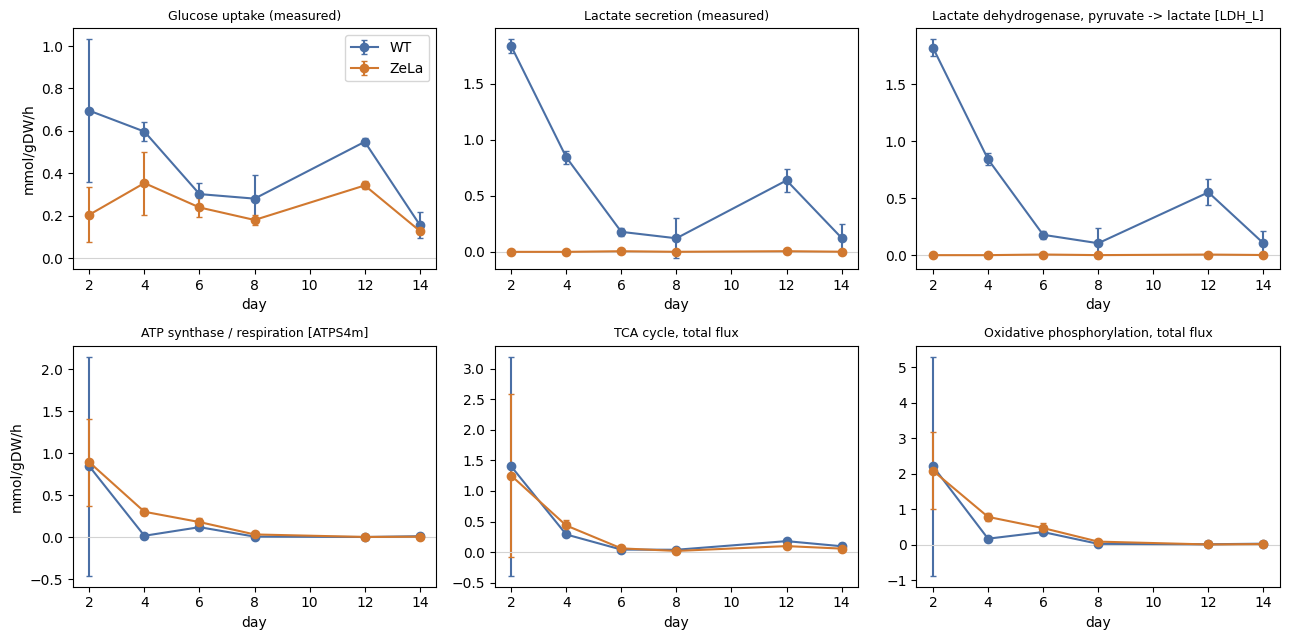

In [7]:
flux = pd.read_parquet(OUT / 'flux_matrix.parquet'); flux.index = flux.index.astype(str)
ft = pd.read_parquet(OUT / 'flux_table.parquet')
ft['sample_id'] = ft.merge(meta.reset_index(), on=['clone', 'timepoint'], how='left')['sample_id'].values
path_total = ft.assign(a=ft.flux.abs()).groupby(['subsystem', 'sample_id']).a.sum().unstack('subsystem')
series = {
    'Glucose uptake (measured)': flux.loc['EX_glc_e'].abs(),
    'Lactate secretion (measured)': flux.loc['EX_lac_L_e'],
    'Lactate dehydrogenase, pyruvate -> lactate [LDH_L]': -flux.loc['LDH_L'],
    'ATP synthase / respiration [ATPS4m]': flux.loc['ATPS4m'],
    'TCA cycle, total flux': path_total['CITRIC ACID CYCLE'],
    'Oxidative phosphorylation, total flux': path_total['OXIDATIVE PHOSPHORYLATION'],
}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5)); axes = axes.ravel()
for ax, (title, v) in zip(axes, series.items()):
    d = meta.assign(v=v)
    for cond, g in d.groupby('condition'):
        m = g.groupby('timepoint').v.agg(['mean', 'std'])
        ax.errorbar(m.index, m['mean'], yerr=m['std'].fillna(0), marker='o', c=COL[cond], capsize=2, label=cond)
    ax.axhline(0, c='lightgrey', lw=0.8); ax.set_title(title, fontsize=9); ax.set_xlabel('day')
axes[0].set_ylabel('mmol/gDW/h'); axes[3].set_ylabel('mmol/gDW/h'); axes[0].legend()
plt.tight_layout(); plt.show()

### 3.3 Where do the two strains differ most?
Mean absolute flux per pathway on days 2-4 (exponential growth), ZeLa relative to WT.

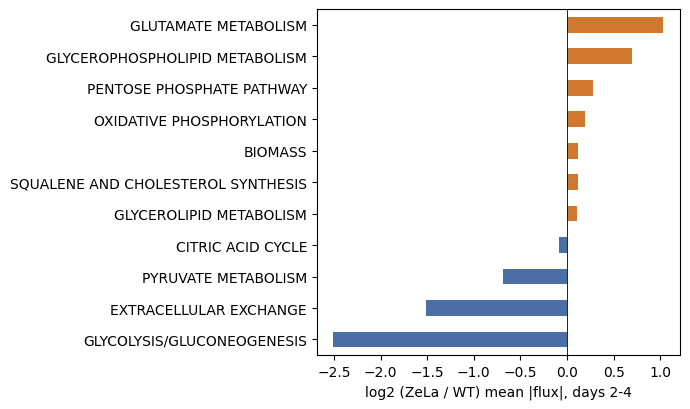

condition,WT,ZeLa,log2 ZeLa/WT
subsystem,,,
GLYCOLYSIS/GLUCONEOGENESIS,0.210,0.037,-2.507
EXTRACELLULAR EXCHANGE,0.529,0.186,-1.507
PYRUVATE METABOLISM,0.005,0.003,-0.684
CITRIC ACID CYCLE,0.042,0.040,-0.083
GLYCEROLIPID METABOLISM,0.000,0.000,0.104
SQUALENE AND CHOLESTEROL SYNTHESIS,0.003,0.003,0.115
BIOMASS,0.021,0.023,0.115
OXIDATIVE PHOSPHORYLATION,0.132,0.151,0.195
PENTOSE PHOSPHATE PATHWAY,0.007,0.008,0.282


In [8]:
early = ft[ft.timepoint <= 4].assign(a=lambda d: d.flux.abs())
by = early.groupby(['subsystem', 'condition']).a.mean().unstack('condition')
by = by[(by > 1e-4).any(axis=1)]
by['log2 ZeLa/WT'] = np.log2((by['ZeLa'] + 1e-6) / (by['WT'] + 1e-6))
by = by.sort_values('log2 ZeLa/WT')
ax = by['log2 ZeLa/WT'].plot.barh(figsize=(7, 4.2), color=['#d1782f' if x > 0 else '#4a6fa5' for x in by['log2 ZeLa/WT']])
ax.axvline(0, c='k', lw=0.6); ax.set(xlabel='log2 (ZeLa / WT) mean |flux|, days 2-4', ylabel='')
plt.tight_layout(); plt.show()
by.round(3)

### 3.4 On a pathway map
Arrow thickness is flux size; red is forward, blue is reverse; grey means the reaction
is not in the model or carries no data. Compare the lactate branch between the two maps.
(Drag to pan, scroll to zoom. The same views are in the app: `streamlit run app/streamlit_app.py`,
dataset **zela**.)

In [9]:
MAP = C.ROOT / 'escher_maps' / 'glycolysis_tca_ppp.json'
print('WT, day 4 (S2)')
ev.show_map(MAP, ev.reaction_data_for_sample(flux, 'S2'), mode='flux', height=520)

WT, day 4 (S2)


/Users/nkranjc/work/gems/.venv/lib/python3.9/site-packages/IPython/core/display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [10]:
print('ZeLa, day 4 (S18)')
ev.show_map(MAP, ev.reaction_data_for_sample(flux, 'S18'), mode='flux', height=520)

ZeLa, day 4 (S18)


## 4. How far to trust this

* **Solid:** exchange fluxes (they are the measurements, lightly adjusted - see
  `exchange_reconciliation.csv`), growth capacity, and the direction of large
  differences between conditions.
* **Indicative:** individual internal fluxes. The model returns one economical solution;
  other flux patterns can fit the same data. iCHO3K has many parallel reactions for the same
  step (isozymes, compartments), so a single reaction id can read zero while its twin carries
  the flux - read **pathway totals** and large differences, not single reactions.
* **Not modelled:** enzyme kinetics, regulation, and product (antibody) synthesis.
* Ethanol secretion was measured in some early samples but the model cannot produce it,
  so the reconciliation sets it to zero - a gap in the model, visible in the report.
* Growth capacity runs about 1.5x the measured growth rate: the default biomass recipe and
  missing costs (antibody, maintenance) make the model a little too efficient.

## 5. Using your own data

Put these in one folder and point the pipeline at it:

| File | Content |
|---|---|
| `counts.csv` | genes x samples (normalised expression) |
| `metadata.csv` | `sample_id, project, clone, condition, timepoint` |
| `exchange_rates.csv` *(optional)* | samples x exchange reactions, mmol/gDW/h, negative = uptake |
| `measured_growth.csv` *(optional)* | `sample_id`, growth rate in 1/h |

```bash
python -m gems.pipeline --raw <folder> --crosswalk <gene crosswalk.tsv> --out results/<name>
```
If you only have concentrations (VCD, glucose, lactate ...) instead of rates, put them in
`metadata.csv` and the pipeline computes rates itself. `scripts/prepare_zela.py` is the
template for building these files.